In [1]:
import os
# Set your own key first: https://api.census.gov/data/key_signup.html
assert os.environ.get("CENSUS_API_KEY"), "Set the CENSUS_API_KEY environment variable"


In [2]:
import numpy as np
import datetime
import matplotlib.pyplot as plt

from epymorph.adrio import acs5, commuting_flows
from epymorph.time import TimeFrame
from epymorph.geography.us_census import StateScope
from epymorph.adrio.cdc import CovidHospitalizationAvgFacility, CovidHospitalizationSumFacility
from epymorph.parameter_fitting.utils.observations import ModelLink, Observations
from epymorph.time import EveryNDays
from epymorph.parameter_fitting.likelihood import Poisson

# =============================================================================
# Global Parameters
# =============================================================================


# gamma       = 0.2           # recovery rate from I
# eta         = 0.05          # hospitalization rate from I
# delta       = 0.1           # discharge rate from H


tau_day   = 1.0 / 3   # 8 h
tau_night = 2.0 / 3   # 16 h  → total 1 day per sub-step
dt         = 1.0      # not used in tau-leap
gamma      = 0.2      # per-day removal rate from I
h_prob     = 200/10000  # fraction of I → H
h_dur      = 5.0      # mean hospital stay (days)
xi         = 1/365    # waning immunity rate R→S
rng        = np.random.default_rng(42)

In [8]:

# 1) set scope/time
scope      = StateScope.in_states(["AZ","NM", "CO", "UT"], year=2020)
time_frame = TimeFrame.range("2021-07-01","2022-04-01")

# 2) get real hospital data
raw = CovidHospitalizationAvgFacility(2).with_context(
    scope=scope, time_frame=time_frame
).evaluate()
#print("raw:", raw)
# raw is structured: each element has fields date & data=(AZ,H),(NM,H)
H_array = np.array([r["data"] for r in raw]).T  # shape (2, n_obs)
print([r["data"] for r in raw][0])
# 3) get population
pop_raw = acs5.Population().with_context(scope=scope, time_frame=time_frame).evaluate()
pop = pop_raw if pop_raw.dtype.names is None else pop_raw["data"]
print("pop:", pop)
print(len(pop))

# 4) get commuting & make mov_ratio
comm = commuting_flows.Commuters().with_context(
    scope=scope, time_frame=time_frame
).evaluate().astype(float)
print("comm:", comm)
mov_ratio = comm / pop[None,:]
print("ratio:", mov_ratio)
n_locations = len(pop)
n_obs       = H_array.shape[1]
print("num of obs:", n_obs)
obs_index   = np.arange(n_obs)
# initial_cond = np.mean(sirh_ensemble, axis=2)

#result = SIRH_tau_leap(pop, mov_ratio, initial_cond, beta, len(time_vector))

# 5) run EnKF
ensemble_size = 2000

/Users/syed/miniconda3/lib/python3.11/site-packages/epymorph/adrio/cdc.py:89: UserWarning: 3109 values < 4 were replaced with 2 in returned data.
  warn(


[373.4 300.9  97.1 222.7]
pop: [7174064 5684926 2097021 3151239]
4
comm: [[3.128890e+06 1.604000e+03 2.996000e+03 3.305000e+03]
 [1.036000e+03 2.887894e+06 2.330000e+03 1.138000e+03]
 [3.275000e+03 2.703000e+03 8.535900e+05 2.140000e+02]
 [1.310000e+03 1.248000e+03 1.970000e+02 1.501339e+06]]
ratio: [[4.36139126e-01 2.82149671e-04 1.42869337e-03 1.04879382e-03]
 [1.44409082e-04 5.07991485e-01 1.11109998e-03 3.61127798e-04]
 [4.56505546e-04 4.75467930e-04 4.07048856e-01 6.79097967e-05]
 [1.82602218e-04 2.19527923e-04 9.39427884e-05 4.76428160e-01]]
num of obs: 39


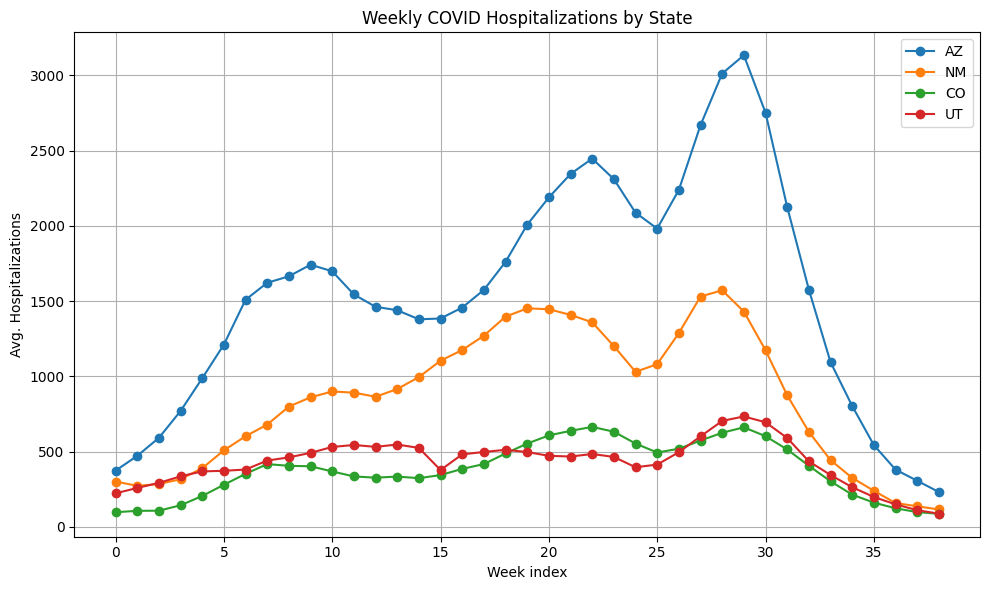

In [4]:
state_names = ["AZ", "NM", "CO", "UT"]

plt.figure(figsize=(10, 6))
for loc_idx, name in enumerate(state_names):
    plt.plot(
        obs_index,
        H_array[loc_idx, :],
        marker='o',
        label=name
    )

plt.xlabel("Week index")
plt.ylabel("Avg. Hospitalizations")
plt.title("Weekly COVID Hospitalizations by State")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
def sirh_model(state, beta_val, dt,
               gamma,          # recovery/hospitalisation rate from I   (1/γ = mean infectious period)
               h_prob,         # fraction of infectious cases that enter H
               h_dur,          # mean hospital length of stay
               xi):            # waning-immunity rate R → S
    """
    One deterministic Euler step for the S–I–R–H model with
      • hospitalisation probability (h_prob),
      • fixed-mean hospital stay (h_dur),
      • waning immunity (xi).

    Parameters
    ----------
    state     : array-like, [S, I, H, R]
    beta_val  : float,   current transmission rate β(t)
    dt        : float,   time step for the Euler update
    gamma     : float,   per-capita removal rate from I
    h_prob    : float,   fraction of removed I that go to H
    h_dur     : float,   average hospital stay (days)
    xi        : float,   per-capita waning-immunity rate
    """
    S, I, H, R = state
    N = max(1.0, S + I + H + R)      # avoid divide-by-zero if population is zero

    # --- ODE increments -----------------------------------------------
    dS = (-beta_val * S * I / N + xi * R) * dt
    dI = ( beta_val * S * I / N - gamma * I ) * dt
    dH = ( gamma * h_prob * I - (1.0 / h_dur) * H ) * dt
    dR = ( gamma * (1.0 - h_prob) * I + (1.0 / h_dur) * H - xi * R ) * dt

    return np.array([S + dS, I + dI, H + dH, R + dR])




def SIRH_tau_leap(population, mov_ratio, init_state, beta_traj, t_steps):
    n_loc = len(population)
    result = np.zeros((n_loc, 4, t_steps))
    result[:,:,0] = init_state

    for t in range(1, t_steps):
        S = result[:,0,t-1].copy()
        I = result[:,1,t-1].copy()
        H = result[:,2,t-1].copy()
        R = result[:,3,t-1].copy()
        β = beta_traj[:,t-1]

        # commuting S,I
        mS = mov_ratio @ np.diag(S)
        mI = mov_ratio @ np.diag(I)
        S = np.clip(S - mS.sum(0), 0, None) + mS.sum(1)
        I = np.clip(I - mI.sum(0), 0, None) + mI.sum(1)

        # --- daytime (8 h) ---
        inf  = β * S * I / population
        new_inf   = rng.poisson(np.clip(tau_day   * inf, 0, None))
        rem_I     = rng.poisson(np.clip(gamma     * I * tau_day, 0, None))
        hosp      = rng.poisson(np.clip(gamma*h_prob * I * tau_day, 0, None))
        disch     = rng.poisson(np.clip(       H / h_dur * tau_day,   0, None))

        S -= new_inf
        I += new_inf - rem_I
        H += hosp - disch
        R += rem_I - hosp + disch

        # --- nighttime (16 h) ---
        inf2 = β * S * I / population
        new_inf2   = rng.poisson(np.clip(tau_night * inf2, 0, None))
        rem_I2     = rng.poisson(np.clip(gamma     * I * tau_night, 0, None))
        hosp2      = rng.poisson(np.clip(gamma*h_prob * I * tau_night, 0, None))
        disch2     = rng.poisson(np.clip(       H / h_dur * tau_night,   0, None))

        S -= new_inf2
        I += new_inf2 - rem_I2
        H += hosp2 - disch2
        R += rem_I2 - hosp2 + disch2

        # store
        result[:,0,t] = np.clip(S,0,None)
        result[:,1,t] = np.clip(I,0,None)
        result[:,2,t] = np.clip(H,0,None)
        result[:,3,t] = np.clip(R,0,None)

    return result



In [13]:
def SIRH_tau_leap_nomove(population, init_state, beta_traj, t_steps):
    """
    Same as before, but no commuting.
    population: 1-d array length = n_states
    init_state: (n_states×4)
    beta_traj:  (n_states×t_steps)
    """
    n_states = len(population)
    result = np.zeros((n_states, 4, t_steps))
    result[:, :, 0] = init_state

    for t in range(1, t_steps):
        S = result[:, 0, t-1].copy()
        I = result[:, 1, t-1].copy()
        H = result[:, 2, t-1].copy()
        R = result[:, 3, t-1].copy()
        β = beta_traj[:, t-1]

        # —- daytime (8 h) —
        inf  = β * S * I / population
        new_inf   = rng.poisson(np.clip(tau_day   * inf, 0, None))
        rem_I     = rng.poisson(np.clip(gamma     * I * tau_day, 0, None))
        hosp      = rng.poisson(np.clip(gamma*h_prob * I * tau_day, 0, None))
        disch     = rng.poisson(np.clip(       H / h_dur  * tau_day, 0, None))

        S -= new_inf
        I += new_inf - rem_I
        H += hosp - disch
        R += rem_I - hosp + disch

        # —- nighttime (16 h) —
        inf2  = β * S * I / population
        new_inf2   = rng.poisson(np.clip(tau_night * inf2, 0, None))
        rem_I2     = rng.poisson(np.clip(gamma      * I * tau_night, 0, None))
        hosp2      = rng.poisson(np.clip(gamma*h_prob * I * tau_night, 0, None))
        disch2     = rng.poisson(np.clip(       H/h_dur  * tau_night, 0, None))

        S -= new_inf2
        I += new_inf2 - rem_I2
        H += hosp2 - disch2
        R += rem_I2 - hosp2 + disch2

        result[:, 0, t] = np.clip(S, 0, None)
        result[:, 1, t] = np.clip(I, 0, None)
        result[:, 2, t] = np.clip(H, 0, None)
        result[:, 3, t] = np.clip(R, 0, None)

    return result

In [16]:


# =============================================================================
# Ensemble Kalman Filter
# =============================================================================

def naive_enkf(N, n_loc, population, mov_ratio, H_obs, obs_index, lambda_max, 
               beta_min, beta_max):
    """
    N:           ensemble size
    n_loc:       number of regions (e.g. 2 for AZ & NM)
    population:  (n_loc,) array
    mov_ratio:   (n_loc,n_loc) commuting matrix
    H_obs:       (n_loc,n_obs) hospitalization obs
    obs_index:   length-n_obs array of indices
    lambda_max:  max initial I
    beta_min, beta_max: bounds for initializing beta
    """
    n_obs = len(obs_index)

    # --- initialize S,I,H,R ensemble ---
    sirh_ensemble = np.zeros((n_loc, 4, N))
    for loc in range(n_loc):
        sirh_ensemble[loc,1,:] = rng.uniform(100, 10000, N) #lambda_max removed
        sirh_ensemble[loc,2,:] = rng.uniform(0,500, N)
        sirh_ensemble[loc,0,:] = population[loc] - sirh_ensemble[loc,1,:] - sirh_ensemble[loc,2,:]
        sirh_ensemble[loc,3,:] = 0

    beta_init = rng.uniform(beta_min, beta_max, (n_locations, N))
    beta_ensemble = np.zeros((n_loc, N, n_obs))
    H_ensemble_kf = np.zeros((n_loc, N, n_obs))
    H_ensemble_kf[:, :, 0] = sirh_ensemble[:, 2, :]
    save_mean = np.zeros((n_loc, 5, n_obs))
    save_mean[:, 0:4, 0] = np.mean(sirh_ensemble, axis=2)
    save_mean[:, 4, 0] = np.mean(beta_init, axis=1)
    save_quantiles = np.zeros((5, n_locations, n_obs))
    H_quantiles = np.zeros((5, n_locations, n_obs))
    H0 = sirh_ensemble[:, 2, :]                # shape (n_loc, N)
    save_quantiles[:, :, 0] = np.quantile(beta_init, [0.05,0.25,0.5,0.75,0.95], axis=1)
    H_quantiles[:, :, 0] = np.quantile(H0, [0.05, 0.25, 0.5, 0.75, 0.95], axis=1)


    # assimilation loop
    for i_obs in range(n_obs - 1):


        # Simulate the model for one time step for all particles
        sirh_next_particles = np.zeros_like(sirh_ensemble)  # Shape (n_locations, 3, N)
        for p in range(N):
        # take the p-th particle’s current state
            init_p = sirh_ensemble[:, :, p]                  # (n_loc, 4)
            beta_p  = beta_init[:, p]                        # (n_loc,)
            # need a (n_loc x t_steps) array for beta trajectory:
            beta_traj = np.repeat(beta_p[:, None], 7, axis=1)  
            out = SIRH_tau_leap(population, mov_ratio, init_p, beta_traj, t_steps=7)
            sirh_next_particles[:, :, p] = out[:, :, -1]                # last sub-step
        sirh_ensemble =  sirh_next_particles  # Update sir_init with the new states for all particles
        #print("pre‐assim H mean:", sirh_ensemble[:,2,:].mean(axis=1))

        # Perturb beta
        beta_init = np.exp(np.log(beta_init) + 0.1 * rng.normal(size=(n_locations, N)))
        # beta_init = np.clip(beta_init, beta_min, beta_max)

        # Clip values to ensure non-negativity
        sir_init = np.clip(sirh_ensemble, 0, None)

        # We want to store the ensemble as a single 2D array. Each column represents the compartment values
        # (SIR) and beta for each location in the order (S_1, I_1, R_1, beta_1, S_2, R_2, ...) where the
        # subscript indicates the location.
        ensemble = np.concatenate((sir_init, beta_init[:, np.newaxis, :]), axis=1)
        n_vars = sir_init.shape[1] + 1
        ensemble = ensemble.reshape((n_locations*n_vars, N))

        # The linear transformation of the state space to the observation space.
        # H will have n_locations rows (one for each observation) and n_vars*n_locations columns (the size of the state space)
        # Each row of H will have a single 1 in it for the I compartment of that location.
        H = np.zeros(shape=(n_locations, n_vars*n_locations))
        for loc in range(n_locations):
            H[loc, 2+loc*n_vars] = 1

        prior_mean = np.mean(ensemble, axis=1)
        prior_cov = np.cov(ensemble)

        observation = H_obs[:, i_obs+1]
        
        # Trick to approximate the Poisson distribution with a Gaussian. We scale the
        # observational covariance according to the size of the observation. Also we
        # want to add a small positive number to ensure it's never zero.
        R_obs = np.diag(observation+0.01)

        K = prior_cov@H.T@np.linalg.inv(R_obs + H@prior_cov@H.T)
        
        # # This is the naive enkf, but the multivariate normal has convergence issues.
        # post_mean = prior_mean[:, np.newaxis] + K@(observation[:, np.newaxis] - H@ensemble)
        # post_cov = prior_cov - K@H@prior_cov
        # post_ensemble = rng.multivariate_normal(mean=post_mean[:, 0], cov=post_cov, size=N).T

        # This is what is usually called the enkf, but it is also known as the stochastic enkf.

        # We have to transpose the output of numpy's multivariate normal to give us the shape we want. 
        eps_ensemble = rng.multivariate_normal(mean=np.zeros(n_locations), cov=R_obs, size=N).T
        post_ensemble = np.zeros(ensemble.shape)
        for i_ens in range(N):
            eps = eps_ensemble[:, i_ens]
            ens_member = ensemble[:, i_ens]
            post_member = ens_member[:, np.newaxis] + K@(observation[:, np.newaxis] - H@ens_member[:, np.newaxis] + eps[:, np.newaxis])
            post_ensemble[:, i_ens] = post_member[:, 0]

        # Reshape and extract to the format that is expected.
        sirh_ensemble = post_ensemble.reshape((n_locations, 5, N))[:, :n_vars-1, :]
        #print("post‐assim H mean:", sirh_ensemble[:,2,:].mean(axis=1))
        beta_init = post_ensemble.reshape((n_locations, 5, N))[:, n_vars-1, :]
        beta_init = np.clip(beta_init, 0.0001, None)
        beta_ensemble[:, :, i_obs+1] = beta_init.copy()
        H_sim = sirh_ensemble[:, 2, :] 
        H_ensemble_kf[:, :, i_obs+1] = sirh_ensemble[:, 2, :]
        # Save results
        save_mean[:, 0:4, i_obs + 1] = np.mean(sirh_ensemble, axis=2)
        save_mean[:, 4, i_obs + 1] = np.mean(beta_init, axis=1)
        save_quantiles[:, :, i_obs + 1] = np.quantile(beta_init, [0.05, 0.25, 0.5, 0.75, 0.95], axis=1)
        H_quantiles[:, :, i_obs+1] = np.quantile(H_sim,[0.05, 0.25, 0.5, 0.75, 0.95],axis=1)

    return sirh_ensemble, save_mean, save_quantiles, beta_ensemble, H_quantiles, H_ensemble_kf
# =============================================================================
# Main Execution
# =============================================================================



In [17]:
sirh_final, mean_hist, quant_hist, beta_ensemble, H_quantiles, H_ensemble_kf = naive_enkf(
    ensemble_size, n_locations, pop, mov_ratio, H_array, obs_index,
    lambda_max=10000, beta_min=0.2, beta_max=0.5
)

pop_r: 7174064


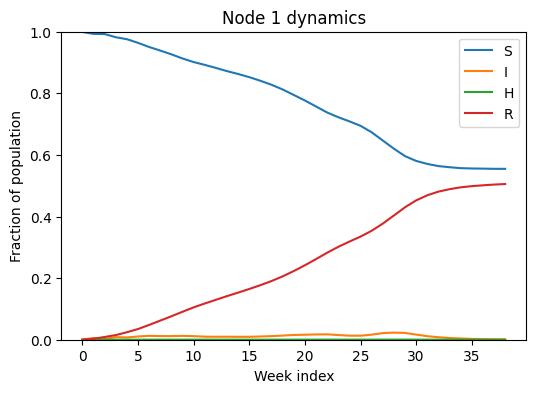

pop_r: 5684926


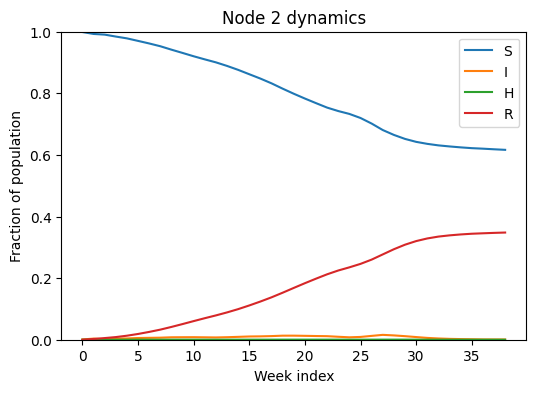

pop_r: 2097021


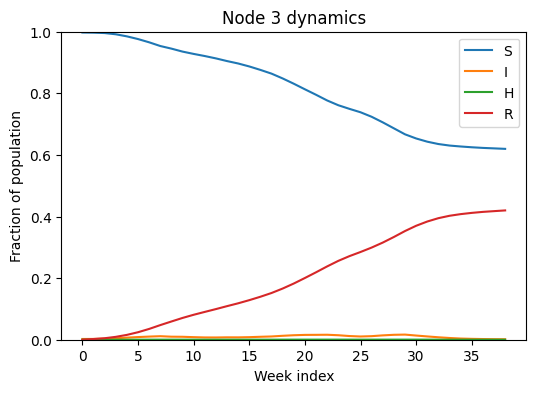

pop_r: 3151239


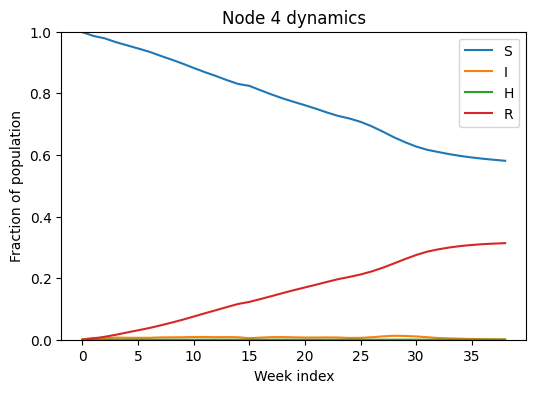

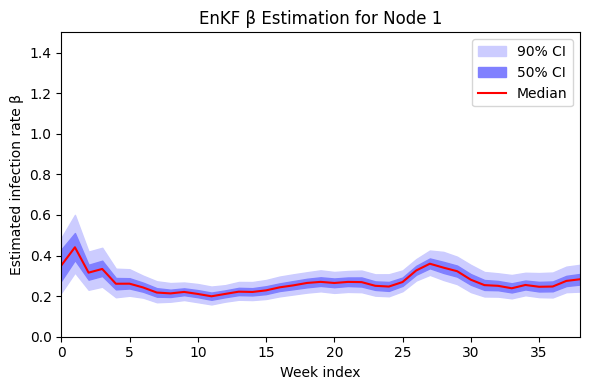

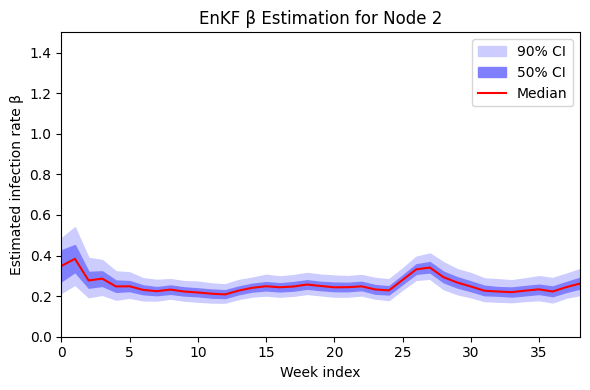

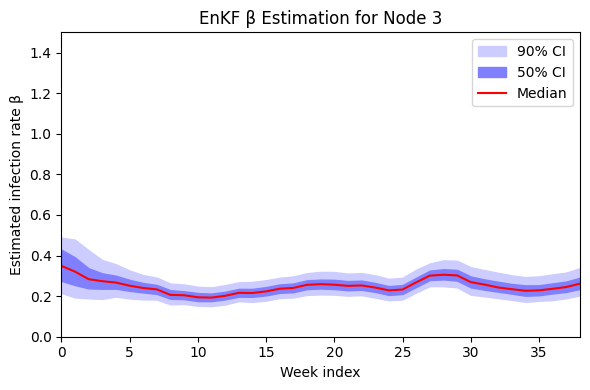

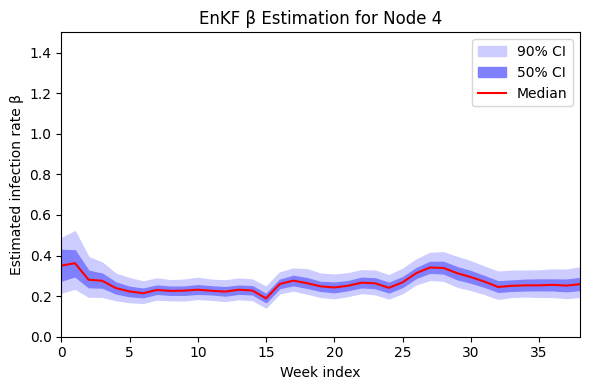

Final beta estimate AZ, NM, CO, UT: [0.2845179  0.26517946 0.26512111 0.26243288]


In [18]:
for node in range(n_locations):
    pop_r = pop[node]
    print("pop_r:", pop_r)
    frac = mean_hist[node,:4,:] / pop_r  # only S,I,H,R
    plt.figure(figsize=(6,4))
    plt.plot(obs_index, frac[0], label='S')
    plt.plot(obs_index, frac[1], label='I')
    plt.plot(obs_index, frac[2], label='H')
    plt.plot(obs_index, frac[3], label='R')
    plt.ylim(0, 1)
    plt.xlabel('Week index')
    plt.ylabel('Fraction of population')
    plt.title(f'Node {node+1} dynamics')
    plt.legend()
    plt.show()


# 6) example plot of estimated vs observed H for AZ
for node_idx in range(n_locations):
    plt.figure(figsize=(6, 4))

    # 90% credible interval
    plt.fill_between(obs_index,
                    quant_hist[0, node_idx, :],
                    quant_hist[4, node_idx, :],
                    color=[0.8, 0.8, 1],
                    label='90% CI')

    # 50% credible interval
    plt.fill_between(obs_index,
                    quant_hist[1, node_idx, :],
                    quant_hist[3, node_idx, :],
                    color=[0.5, 0.5, 1],
                    label='50% CI')

    # Median estimate
    plt.plot(obs_index,
            quant_hist[2, node_idx, :],
            'r-',
            label='Median')

    plt.xlabel('Week index')
    plt.ylabel('Estimated infection rate β')
    plt.ylim([0, 1.5])
    plt.xlim([obs_index[0], obs_index[-1]])
    plt.title(f'EnKF β Estimation for Node {node_idx+1}')
    plt.legend()
    plt.tight_layout()
    plt.show()

# 7) final beta estimates
print("Final beta estimate AZ, NM, CO, UT:", mean_hist[:,4,-1])


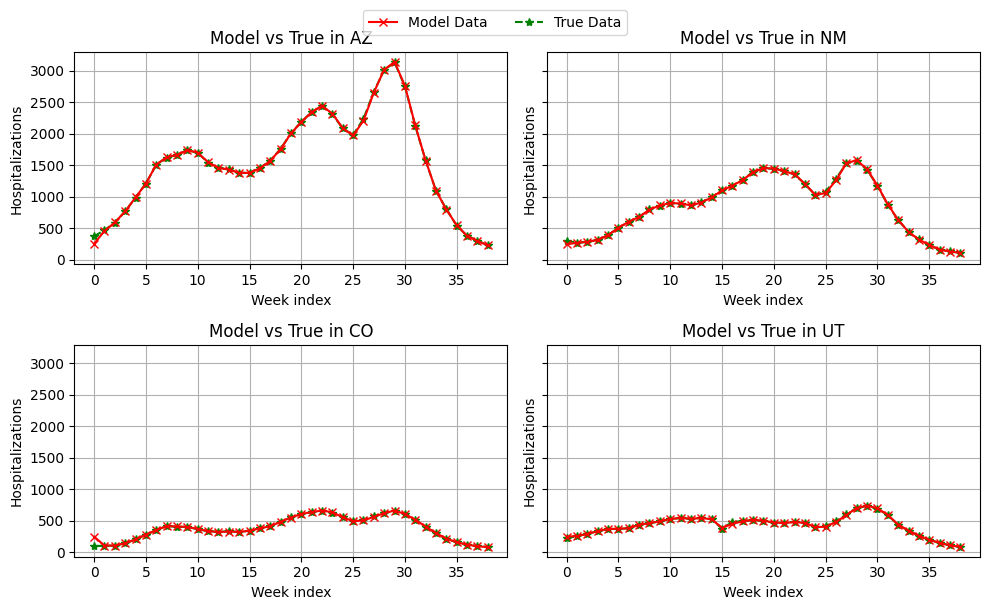

In [19]:
# after
#   sirh_final, mean_hist, quant_hist, beta_ensemble = naive_enkf(…)
#   H_array  # shape (n_locations, n_obs)

state_names = ["AZ", "NM", "CO", "UT"]  # in the same order as your scope/states
model_data  = mean_hist[:, 2, :]        # (n_locations, n_obs) – the H estimates
true_data   = H_array                   # (n_locations, n_obs)

fig, axs = plt.subplots(2, 2, sharey=True, figsize=(10, 6))
axs = axs.ravel()

for i_ax, ax in enumerate(axs):
    ax.plot(
        model_data[i_ax, :],
        label="Model Data",
        color="red",
        linestyle="-",
        marker="x",
        zorder=10,
    )
    ax.plot(
        true_data[i_ax, :],
        label="True Data",
        color="green",
        linestyle="--",
        marker="*",
        zorder=9,
    )
    ax.set_xlabel("Week index")
    ax.set_ylabel("Hospitalizations")
    ax.set_title(f"Model vs True in {state_names[i_ax]}")
    ax.grid(True)

# put one legend for the entire figure
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()


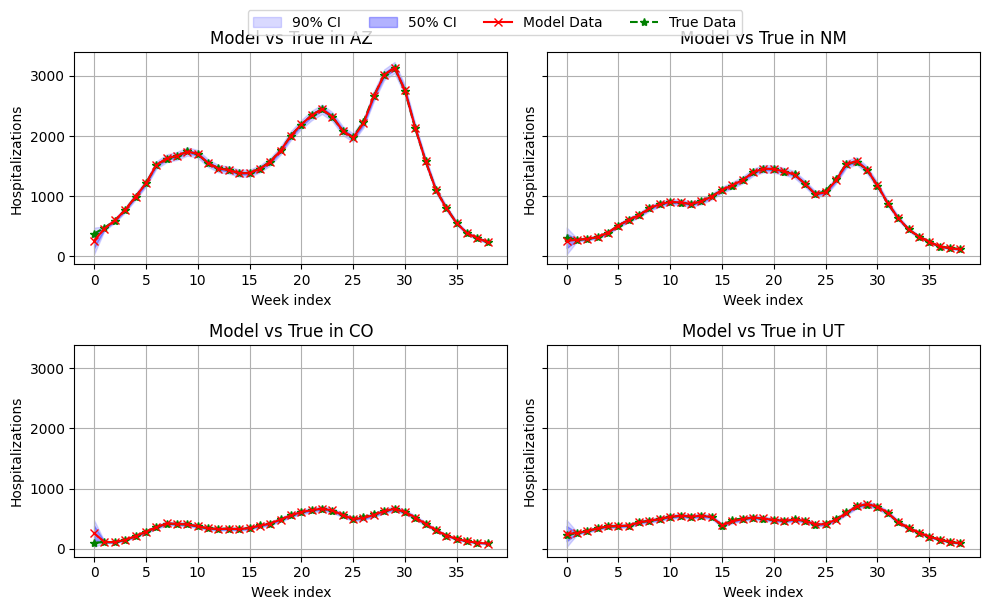

In [45]:
state_names = ["AZ", "NM", "CO", "UT"]
model_data  = mean_hist[:, 2, :]   # median H estimates
true_data   = H_array              # observed H

# unpack quantiles
q05, q25, q50, q75, q95 = H_quantiles

fig, axs = plt.subplots(2, 2, sharey=True, figsize=(10, 6))
axs = axs.ravel()

for i_ax, ax in enumerate(axs):
    t = obs_index

    # 90% credible interval (5–95%)
    ax.fill_between(t,
                    q05[i_ax],
                    q95[i_ax],
                    color="blue",
                    alpha=0.15,
                    label="90% CI")

    # 50% credible interval (25–75%)
    ax.fill_between(t,
                    q25[i_ax],
                    q75[i_ax],
                    color="blue",
                    alpha=0.30,
                    label="50% CI")

    # median forecast
    ax.plot(t,
            model_data[i_ax],
            color="red",
            linestyle="-",
            marker="x",
            zorder=10,
            label="Model Data")

    # true data
    ax.plot(t,
            true_data[i_ax],
            color="green",
            linestyle="--",
            marker="*",
            zorder=9,
            label="True Data")

    ax.set_xlabel("Week index")
    ax.set_ylabel("Hospitalizations")
    ax.set_title(f"Model vs True in {state_names[i_ax]}")
    ax.grid(True)

# single legend
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc="upper center",
           ncol=4,
           bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()


In [18]:
from scipy.stats import poisson
import scipy as sp
from scipy.special import logsumexp

def pf_multinode(N, n_loc, population, mov_ratio, H_obs, obs_index, lambda_max, beta_min, beta_max):
    
    n_obs = len(obs_index)
    # Initialize SIR states for all particles and locations
    sirh_ensemble = np.zeros((n_loc, 4, N))
    for loc in range(n_loc):
        sirh_ensemble[loc,1,:] = rng.uniform(100, 10000, N) #lambda_max removed
        sirh_ensemble[loc,2,:] = rng.uniform(0,500, N)
        sirh_ensemble[loc,0,:] = population[loc] - sirh_ensemble[loc,1,:] - sirh_ensemble[loc,2,:]
        sirh_ensemble[loc,3,:] = 0

    # Uniform weights for all locations
    # weights = np.ones((n_locations, N)) / N
    weights = np.ones((N,)) / N

    # Initialize beta for all particles and locations
    beta_init = rng.uniform(beta_min, beta_max, (n_locations, N))
    # beta_init = rng.uniform(low=0.01, high=1, size=(n_locations, N))

    save_mean = np.zeros((n_loc, 5, n_obs))
    save_mean[:, 0:4, 0] = np.mean(sirh_ensemble, axis=2)
    save_mean[:, 4, 0] = np.mean(beta_init, axis=1)
    save_quantiles = np.zeros((5, n_locations, n_obs))
    H_quantiles = np.zeros((5, n_locations, n_obs))
    H_ensemble_pf = np.zeros((n_loc, N, n_obs))
    H_ensemble_pf[:, :, 0] = sirh_ensemble[:, 2, :]
    H0 = sirh_ensemble[:, 2, :]                # shape (n_loc, N)
    save_quantiles[:, :, 0] = np.quantile(beta_init, [0.05,0.25,0.5,0.75,0.95], axis=1)
    H_quantiles[:, :, 0] = np.quantile(H0, [0.05, 0.25, 0.5, 0.75, 0.95], axis=1)

    # Loop over observations
    for i_obs in range(n_obs - 1):
        # Simulate the model for one time step for all particles
        sirh_next_particles = np.zeros_like(sirh_ensemble)  # Shape (n_locations, 3, N)
        for p in range(N):
        # take the p-th particle’s current state
            init_p = sirh_ensemble[:, :, p]  # (n_loc, 4)
            beta_p  = beta_init[:, p]# (n_loc,)
            # need a (n_loc x t_steps) array for beta trajectory:
            beta_traj = np.repeat(beta_p[:, None], 7, axis=1)  
            out = SIRH_tau_leap(population, mov_ratio, init_p, beta_traj, t_steps=7)
            sirh_next_particles[:, :, p] = out[:, :, -1]                # last sub-step
        sirh_ensemble =  sirh_next_particles  # Update sir_init with the new states for all particles
        print("pre‐assim H mean:", sirh_ensemble[:,2,:].mean(axis=1))
        # Perturb beta
        beta_init = np.exp(np.log(beta_init) + 0.1 * rng.normal(size=(n_locations, N)))
        # beta_init = np.clip(beta_init, beta_min, beta_max)

        # Clip values to ensure non-negativity
        sirh_ensemble = np.clip(sirh_ensemble, 0, None)

        # Update weights based on observations
        # for loc in range(n_locations):
        #     H_obs_val = H_obs[loc, i_obs + 1]  # Observed infected data
        #     H_sim  = sirh_ensemble[loc, 2, :]
        #     # B_sim = beta_init[loc, :] * (I / population[loc]) * S
        #     # Compute the Poisson likelihood
        #     weights *= poisson.pmf(H_sim, H_obs_val) + 1e-2
        #     print(weights)
        #     #weights *= sp.stats.norm.pdf(H_sim, loc=H_obs_val, scale=np.sqrt(H_obs_val) + + 1e-3)

        # # Handle potential zero or NaN weights
        # if np.sum(weights) == 0:
        #     weights = np.ones(N) / N
        # else:
        #     weights /= np.sum(weights)

        # # Resampling

        # u = np.arange(0, 1, 1.0 / N) + 1.0 / N * rng.uniform()
        # c = np.cumsum(weights)
        # idx_ens = np.zeros(N, dtype=int)
        # p = 0
        # for i_ens in range(N):
        #     while u[i_ens] > c[p]:
        #         p += 1
        #     idx_ens[i_ens] = p

        # sirh_ensemble = sirh_ensemble[:, :, idx_ens]
        # beta_init = beta_init[:, idx_ens]
        
        # weights = np.ones((N,)) / N
    # … propagate sirh_ensemble and perturb beta_init …

    # 1) Compute log-weights
        logw = np.zeros(N, dtype=float)
        for loc in range(n_loc):
            mu    = H_obs[loc, i_obs+1]                   # observed hospitalizations
            k_sim = np.floor(sirh_ensemble[loc, 2, :]).astype(int)
            logw += poisson.logpmf(k_sim, mu + 0.001)             # add location’s log-likelihood

    # 2) Normalize in log space
        try:
            shifted = logw - np.max(logw, keepdims=True)
        except FloatingPointError:
            shifted = np.zeros_like(logw)
            print("::::::")

        # clip extremely small values to avoid underflow in exp()
        underflow_lb = -1e2
        clipped = np.clip(shifted, a_min=underflow_lb, a_max=None)

        # exponentiate and normalize
        w = np.exp(clipped)
        if not np.isfinite(w).all() or w.sum() == 0:
            weights = np.ones(N) / N
            print("-------------")
        else:
            weights = w / w.sum()
        
        #weights = np.maximum(weights, 1)
        #weights = weights/weights.sum()
        
        # 4) Systematic resampling
        u    = (np.arange(N) + rng.random()) / N
        c    = np.cumsum(weights)
        idx  = np.searchsorted(c, u, side="right")
        #print("idxxx:", idx)
        sirh_ensemble = sirh_ensemble[:, :, idx]
        beta_init     = beta_init[:, idx]
        weights       = np.ones(N)/N

        H_t = sirh_ensemble[:,2,:]
        H_ensemble_pf[:, :, i_obs+1] = sirh_ensemble[:, 2, :]
        # Save results
        save_mean[:, 0:4, i_obs + 1] = np.mean(sirh_ensemble, axis=2)
        save_mean[:, 4, i_obs + 1] = np.mean(beta_init, axis=1)
        # save_mean[:, 3, i_obs + 1] = beta_init[:, 200]
        save_quantiles[:, :, i_obs + 1] = np.quantile(beta_init, [0.05, 0.25, 0.5, 0.75, 0.95], axis=1)
        H_quantiles[:,:, i_obs+1] = np.quantile(H_t, [0.05,0.25,0.5,0.75,0.95], axis=1)

    return sirh_ensemble, save_mean, save_quantiles, H_quantiles, H_ensemble_pf


In [13]:
ensemble_size = 2000

In [19]:
sirh_final_pf, mean_hist_pf, quant_hist_pf, H_quantiles_pf, H_ensemble_pf = pf_multinode(
    ensemble_size, n_locations, pop, mov_ratio, H_array, obs_index,
    lambda_max=10000, beta_min=0.2, beta_max=0.5
)

pre‐assim H mean: [193.20035121 195.40710003 193.18169268 195.92137187]
pre‐assim H mean: [1245.19502243  457.26594379  275.88354626  601.96066779]
pre‐assim H mean: [2050.1581757   503.50080395  458.89530541  888.20497719]
pre‐assim H mean: [3920.7296757   877.21030395  909.03080541 1570.72397719]
pre‐assim H mean: [6337.3006757   927.15280395 2243.36330541 1849.15047719]
pre‐assim H mean: [9279.1266757  1322.18080395 3723.76030541 2185.63147719]
pre‐assim H mean: [10825.2641757   1774.77330395  4489.24780541  2349.49797719]
pre‐assim H mean: [8431.2881757  2219.48080395 4238.62430541 1960.34597719]
pre‐assim H mean: [6187.5311757  2741.69380395 3215.49730541 1666.71447719]
pre‐assim H mean: [4210.1256757  2984.22480395 2180.16930541 1423.01647719]
pre‐assim H mean: [2763.3906757  2520.82930395 1288.58280541 1275.84047719]
pre‐assim H mean: [1869.1141757  2006.76780395  784.08980541 1057.43847719]
pre‐assim H mean: [1206.8211757  1540.52280395  487.28030541  836.93497719]
pre‐assim H 

pop_r: 7174064


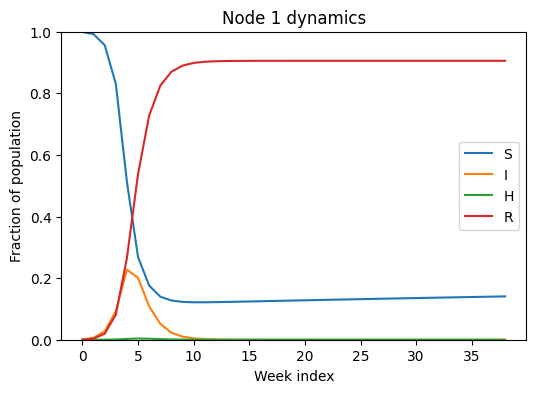

pop_r: 5684926


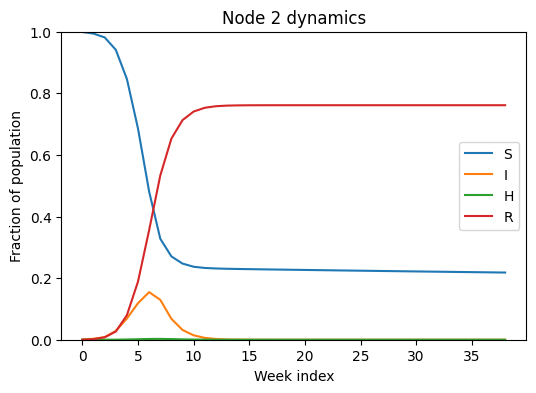

pop_r: 2097021


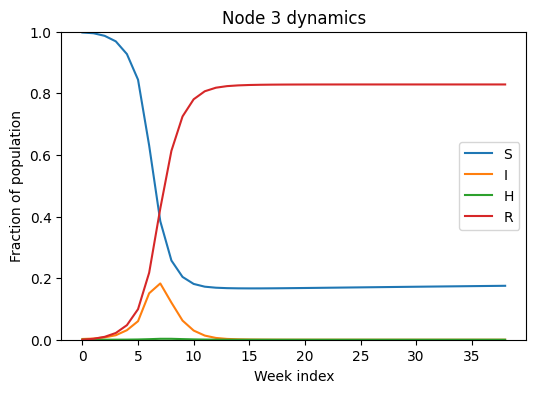

pop_r: 3151239


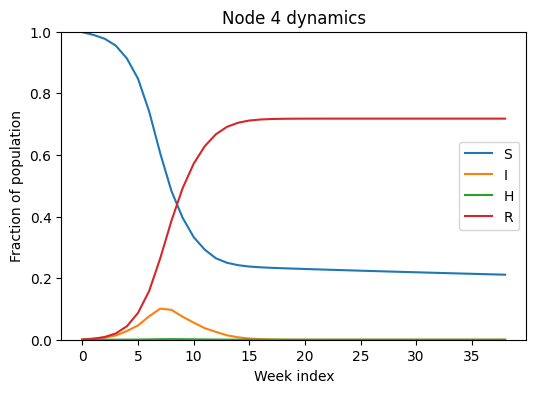

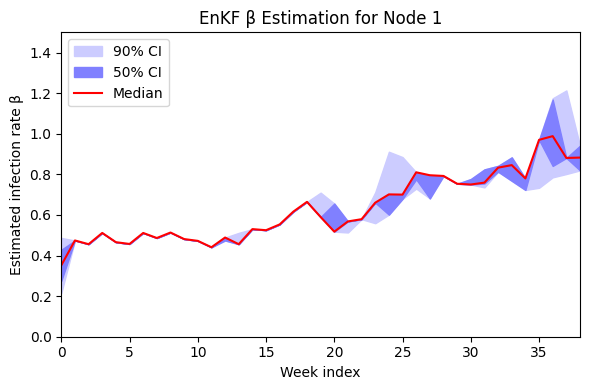

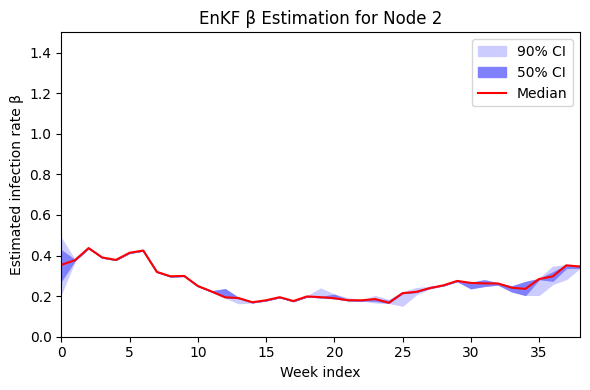

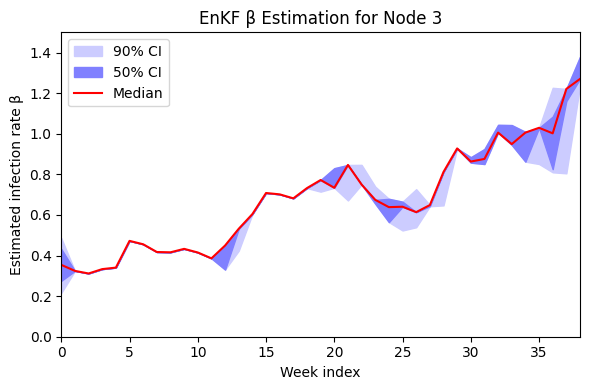

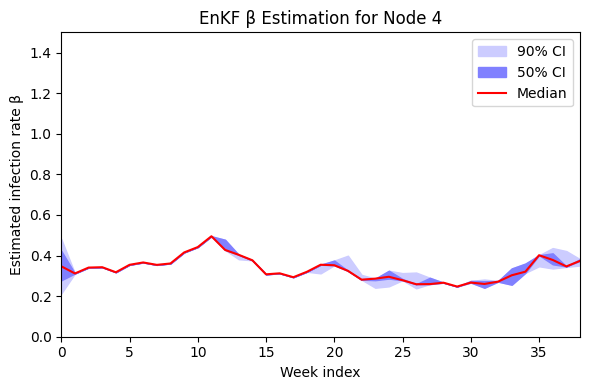

Final beta estimate AZ, NM, CO, UT: [0.88526979 0.34421957 1.31243766 0.37527602]


In [9]:
for node in range(n_locations):
    pop_r = pop[node]
    print("pop_r:", pop_r)
    frac = mean_hist_pf[node,:4,:] / pop_r  # only S,I,H,R
    plt.figure(figsize=(6,4))
    plt.plot(obs_index, frac[0], label='S')
    plt.plot(obs_index, frac[1], label='I')
    plt.plot(obs_index, frac[2], label='H')
    plt.plot(obs_index, frac[3], label='R')
    plt.ylim(0, 1)
    plt.xlabel('Week index')
    plt.ylabel('Fraction of population')
    plt.title(f'Node {node+1} dynamics')
    plt.legend()
    plt.show()


# 6) example plot of estimated vs observed H for AZ
for node_idx in range(n_locations):
    plt.figure(figsize=(6, 4))

    # 90% credible interval
    plt.fill_between(obs_index,
                    quant_hist_pf[0, node_idx, :],
                    quant_hist_pf[4, node_idx, :],
                    color=[0.8, 0.8, 1],
                    label='90% CI')

    # 50% credible interval
    plt.fill_between(obs_index,
                    quant_hist_pf[1, node_idx, :],
                    quant_hist_pf[3, node_idx, :],
                    color=[0.5, 0.5, 1],
                    label='50% CI')

    # Median estimate
    plt.plot(obs_index,
            quant_hist_pf[2, node_idx, :],
            'r-',
            label='Median')

    plt.xlabel('Week index')
    plt.ylabel('Estimated infection rate β')
    plt.ylim([0, 1.5])
    plt.xlim([obs_index[0], obs_index[-1]])
    plt.title(f'EnKF β Estimation for Node {node_idx+1}')
    plt.legend()
    plt.tight_layout()
    plt.show()

# 7) final beta estimates
print("Final beta estimate AZ, NM, CO, UT:", mean_hist_pf[:,4,-1])


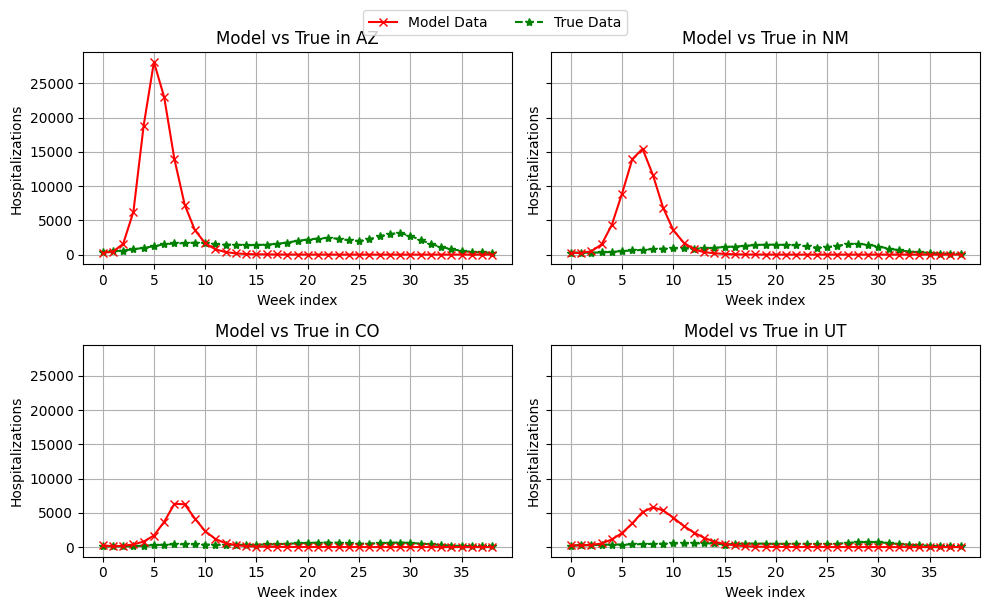

In [10]:
# after
#   sirh_final, mean_hist, quant_hist, beta_ensemble = naive_enkf(…)
#   H_array  # shape (n_locations, n_obs)

state_names = ["AZ", "NM", "CO", "UT"]  # in the same order as your scope/states
model_data_pf  = mean_hist_pf[:, 2, :]        # (n_locations, n_obs) – the H estimates
true_data_pf   = H_array                   # (n_locations, n_obs)

fig, axs = plt.subplots(2, 2, sharey=True, figsize=(10, 6))
axs = axs.ravel()

for i_ax, ax in enumerate(axs):
    ax.plot(
        model_data_pf[i_ax, :],
        label="Model Data",
        color="red",
        linestyle="-",
        marker="x",
        zorder=10,
    )
    ax.plot(
        true_data_pf[i_ax, :],
        label="True Data",
        color="green",
        linestyle="--",
        marker="*",
        zorder=9,
    )
    ax.set_xlabel("Week index")
    ax.set_ylabel("Hospitalizations")
    ax.set_title(f"Model vs True in {state_names[i_ax]}")
    ax.grid(True)

# put one legend for the entire figure
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()


In [6]:
state_names = ["AZ", "NM", "CO", "UT"]
model_data_pf  = mean_hist_pf[:, 2, :]   # median H estimates
true_data_pf   = H_array              # observed H

# unpack quantiles
q05, q25, q50, q75, q95 = H_quantiles_pf

fig, axs = plt.subplots(2, 2, sharey=True, figsize=(12, 8))
axs = axs.ravel()

for i_ax, ax in enumerate(axs):
    t = obs_index

    # 90% credible interval (5–95%)
    ax.fill_between(t,
                    q05[i_ax],
                    q95[i_ax],
                    color="blue",
                    alpha=0.15,
                    label="90% CI")

    # 50% credible interval (25–75%)
    ax.fill_between(t,
                    q25[i_ax],
                    q75[i_ax],
                    color="blue",
                    alpha=0.30,
                    label="50% CI")

    # median forecast
    ax.plot(t,
            model_data_pf[i_ax],
            color="red",
            linestyle="-",
            marker="x",
            zorder=10,
            label="Model Data")

    # true data
    ax.plot(t,
            true_data_pf[i_ax],
            color="green",
            linestyle="--",
            marker="*",
            zorder=9,
            label="True Data")

    ax.set_xlabel("Week index")
    ax.set_ylabel("Hospitalizations")
    ax.set_title(f"Model vs True in {state_names[i_ax]}")
    ax.grid(True)

# single legend
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc="upper center",
           ncol=4,
           bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()


NameError: name 'mean_hist_pf' is not defined

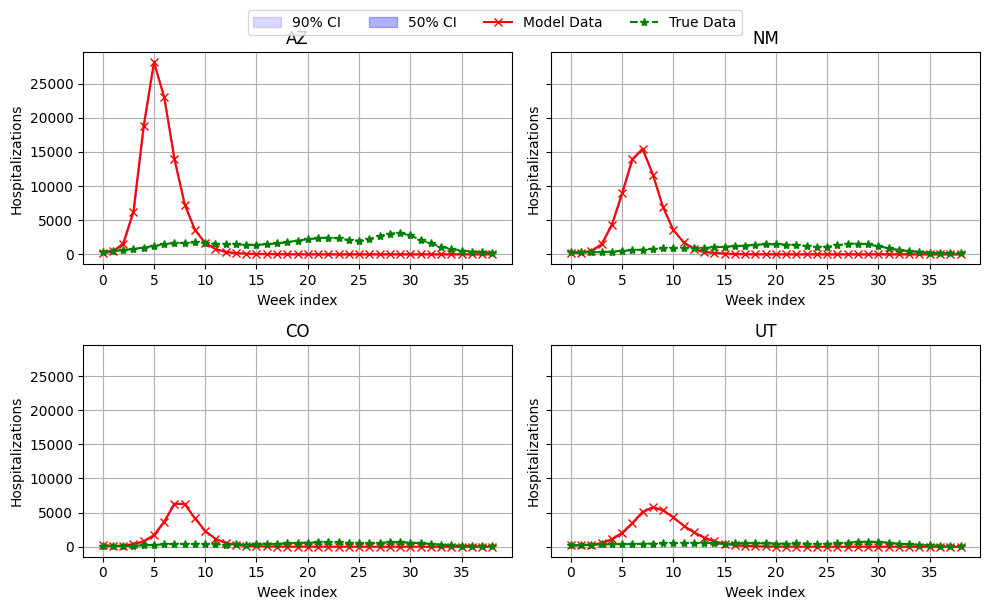

In [12]:
fig, axs = plt.subplots(2, 2, sharey=True, figsize=(10, 6))
axs = axs.ravel()

padding = 50  # how wide you’d like the band at least to be

for i, ax in enumerate(axs):
    t = obs_index

    # inflate the quantile ribbon
    lo90 = q05[i] - padding
    hi90 = q95[i] + padding
    lo50 = q25[i] - padding/2
    hi50 = q75[i] + padding/2

    ax.fill_between(t, lo90, hi90, color="blue", alpha=0.15, label="90% CI")
    ax.fill_between(t, lo50, hi50, color="blue", alpha=0.30, label="50% CI")

    ax.plot(t, model_data_pf[i],    "xr-", label="Model Data")
    ax.plot(t, true_data_pf[i], "*g--", label="True Data")

    ax.set_title(state_names[i])
    ax.set_xlabel("Week index")
    ax.set_ylabel("Hospitalizations")
    ax.grid(True)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()


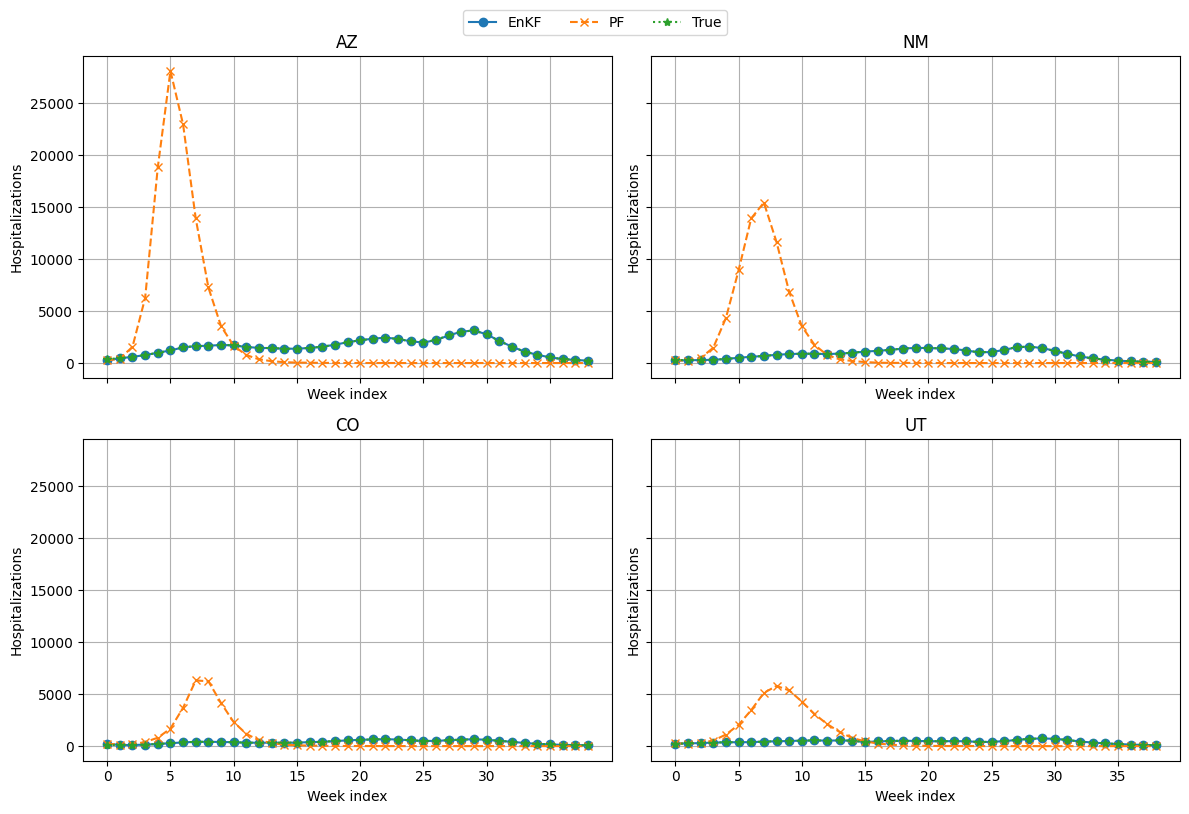

In [21]:
import matplotlib.pyplot as plt

state_names = ["AZ", "NM", "CO", "UT"]

enkf_H = mean_hist[:,     2, :]   # shape (4, T)
pf_H   = mean_hist_pf[:,  2, :]   # shape (4, T)
true_H = H_array                  # shape (4, T)
T      = true_H.shape[1]

fig, axes = plt.subplots(
    nrows=2, ncols=2,
    figsize=(12, 8),
    sharex=True, sharey=True
)
axes = axes.ravel()

for i, ax in enumerate(axes):
    t = np.arange(T)

    # EnKF curve
    ax.plot(t, enkf_H[i],  marker="o", linestyle="-",  color="C0", label="EnKF")
    # PF curve
    ax.plot(t, pf_H[i],    marker="x", linestyle="--", color="C1", label="PF")
    # True data
    ax.plot(t, true_H[i],  marker="*", linestyle=":",  color="C2", label="True")

    ax.set_title(state_names[i])
    ax.set_xlabel("Week index")
    ax.set_ylabel("Hospitalizations")
    ax.grid(True)

# One legend for all
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()


In [3]:
pip install properscoring


Note: you may need to restart the kernel to use updated packages.


In [21]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from properscoring import crps_ensemble

metrics = {}

# PF block
H_hat_pf   = mean_hist_pf[:, 2, :]   # (n_loc, T)
H_true     = H_array                 # (n_loc, T)
lb90_pf    = H_quantiles_pf[0]       # (n_loc, T)
ub90_pf    = H_quantiles_pf[4]       # (n_loc, T)
lb50_pf    = H_quantiles_pf[1]
ub50_pf    = H_quantiles_pf[3]
H_ens_pf   = H_ensemble_pf           # (n_loc, N, T)

metrics["PF"] = {}
metrics["PF"]["MAE"]  = mean_absolute_error(H_true.ravel(), H_hat_pf.ravel())
metrics["PF"]["RMSE"] = np.sqrt(mean_squared_error(H_true.ravel(), H_hat_pf.ravel()))

# coverage
metrics["PF"]["CVG90"] = ((H_true >= lb90_pf) & (H_true <= ub90_pf)).mean()
metrics["PF"]["CVG50"] = ((H_true >= lb50_pf) & (H_true <= ub50_pf)).mean()

# sharpness
metrics["PF"]["Width90"] = (ub90_pf - lb90_pf).mean()

# CRPS
pf_crps = []
for loc in range(n_locations):
    # transpose to (T, N)
    pf_crps.append(crps_ensemble(H_true[loc], H_ens_pf[loc].T).mean())
metrics["PF"]["CRPS"] = np.mean(pf_crps)


# EnKF block
H_hat_enkf = mean_hist[:, 2, :]      # (n_loc, T)
H_ens_enkf = H_ensemble_kf         # (n_loc, N, T)
q_enkf     = np.quantile(H_ens_enkf, [0.05, 0.25, 0.75, 0.95], axis=1)
lb90_e, lb50_e, ub50_e, ub90_e = q_enkf

metrics["EnKF"] = {}
metrics["EnKF"]["MAE"]  = mean_absolute_error(H_true.ravel(), H_hat_enkf.ravel())
metrics["EnKF"]["RMSE"] = np.sqrt(mean_squared_error(H_true.ravel(), H_hat_enkf.ravel()))
metrics["EnKF"]["CVG90"] = ((H_true >= lb90_e) & (H_true <= ub90_e)).mean()
metrics["EnKF"]["CVG50"] = ((H_true >= lb50_e) & (H_true <= ub50_e)).mean()
metrics["EnKF"]["Width90"] = (ub90_e - lb90_e).mean()

enkf_crps = []
for loc in range(n_locations):
    enkf_crps.append(crps_ensemble(H_true[loc], H_ens_enkf[loc].T).mean())
metrics["EnKF"]["CRPS"] = np.mean(enkf_crps)


import pandas as pd
df = pd.DataFrame(metrics).T
print(df)


              MAE         RMSE     CVG90     CVG50   Width90         CRPS
PF    1018.022845  1638.542635  0.038462  0.012821  18.62934  1016.295767
EnKF     6.036914    17.412653  1.000000  0.974359  93.58578     7.937945


In [78]:
import numpy as np
from epymorph.adrio import commuting_flows
from epymorph.kit import *
from epymorph.adrio import acs5
from epymorph.initializer import Proportional

In [79]:
states = ["AZ", "NM", "CO", "UT"]

rume = SingleStrataRUME.build(
    ipm=ipm.SIRH(),
    mm=mm.Pei(),
    scope=StateScope.in_states(states, year=2020),
    init=Proportional(
        ratios=np.broadcast_to(
            np.array([9999, 1, 0, 0], dtype=np.int64), shape=(len(states), 4)
        )
    ),
    time_frame = TimeFrame.range("2021-07-01","2022-04-01"),

# 2) get real hospital data
# raw = CovidHospitalizationAvgFacility(2).with_context(
#     scope=scope, time_frame=time_frame
# ).evaluate()
    params={
        "beta": 0.3,  # Placeholder value
        "gamma": 0.2,
        "xi": 1 / 365,
        "hospitalization_prob": 200 / 100_000,
        "hospitalization_duration": 5.0,
        "population": acs5.Population(),
    },
)

In [80]:
from epymorph.parameter_fitting.distribution import Uniform
from epymorph.parameter_fitting.utils.parameter_estimation import EstimateParameters
from epymorph.parameter_fitting.dynamics import GeometricBrownianMotion

params_space = {
    "beta": EstimateParameters.TimeVarying(
        distribution=Uniform(a=0.1, b=0.8),
        dynamics=GeometricBrownianMotion(volatility=0.1),
    ),
}

In [81]:
from epymorph.adrio.cdc import InfluenzaHospitalizationSumState
from epymorph.adrio.cdc import CovidHospitalizationAvgFacility, CovidHospitalizationSumFacility
from epymorph.parameter_fitting.likelihood import Poisson
from epymorph.parameter_fitting.utils.observations import ModelLink, Observations
from epymorph.time import EveryNDays

observations = Observations(
    source=CovidHospitalizationAvgFacility(2),
    model_link=ModelLink(
        quantity=rume.ipm.select.events("I->H"),
        time=rume.time_frame.select.all(),
        geo=rume.scope.select.all(),
    ),
    likelihood=Poisson(),
)

# # 2) get real hospital data
# raw = CovidHospitalizationAvgFacility(2).with_context(
#     scope=scope, time_frame=time_frame
# ).evaluate()

In [82]:
from epymorph.parameter_fitting.filter.particle_filter import ParticleFilter

filter_type = ParticleFilter(num_particles=1000)

In [83]:
from epymorph.parameter_fitting.particlefilter_simulation import FilterSimulation

sim = FilterSimulation(
    rume=rume,
    observations=observations,
    filter_type=filter_type,
    params_space=params_space,
)

DataAttributeError: Cannot evaluate parameters, there are missing values:
gpm:all::mm::commuters

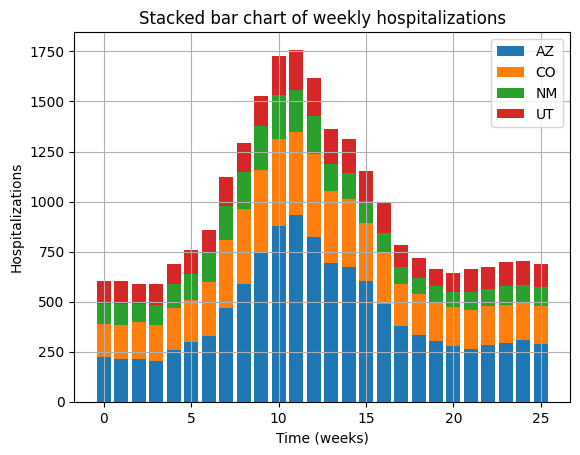

In [10]:
import matplotlib.pyplot as plt

time_axis = range(len(sim.cases))

n_nodes = sim.cases.shape[1]
for i_node in range(n_nodes):
    plt.bar(
        time_axis,
        sim.cases[:, i_node],
        bottom=sim.cases[:, 0:i_node].sum(axis=1),
        label=rume.scope.labels[i_node],
    )

plt.title("Stacked bar chart of weekly hospitalizations")
plt.grid(True)
plt.xlabel("Time (weeks)")
plt.ylabel("Hospitalizations")
plt.legend()
plt.show()

In [20]:
output = sim.run()

Running Particle Filter simulation
• 2022-09-18 00:00:00 to 2023-03-12 00:00:00 (183 days)
• 1000 particles

Simulation completed in 146.59s

Parameters estimated: ['beta']


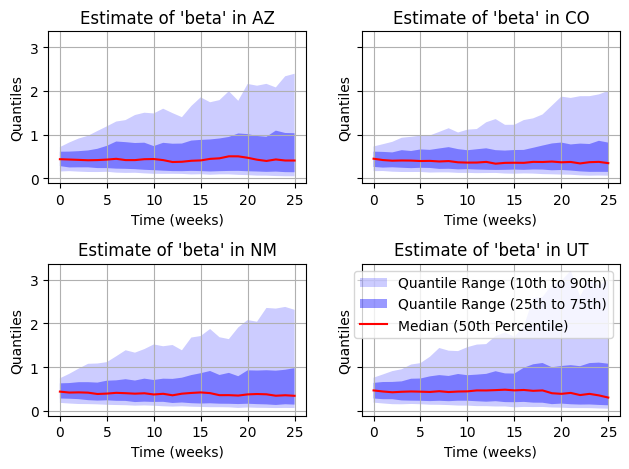

In [21]:
fig, axs = plt.subplots(2, 2, sharey=True)

key = "beta"
key_quantiles = np.array(output.param_quantiles[key])
t = np.arange(0, len(key_quantiles))

axs = np.ravel(axs)
for i_ax in range(len(axs)):
    ax = axs[i_ax]

    ax.fill_between(
        t,
        key_quantiles[:, 3, i_ax],
        key_quantiles[:, 22 - 3, i_ax],
        facecolor="blue",
        alpha=0.2,
        label="Quantile Range (10th to 90th)",
    )
    ax.fill_between(
        t,
        key_quantiles[:, 6, i_ax],
        key_quantiles[:, 22 - 6, i_ax],
        facecolor="blue",
        alpha=0.4,
        label="Quantile Range (25th to 75th)",
    )

    ax.plot(
        t,
        key_quantiles[:, 11, i_ax],
        color="red",
        label="Median (50th Percentile)",
    )

    ax.set_title(f"Estimate of '{key}' in {rume.scope.labels[i_ax]}")
    ax.set_xlabel("Time (weeks)")
    ax.set_ylabel("Quantiles")
    ax.grid(True)

plt.legend()
plt.tight_layout()
plt.show()